Data already downloaded (udhr.zip found). Skipping download.
Reading files from: udhr_data/udhr
Plotting 169 languages...


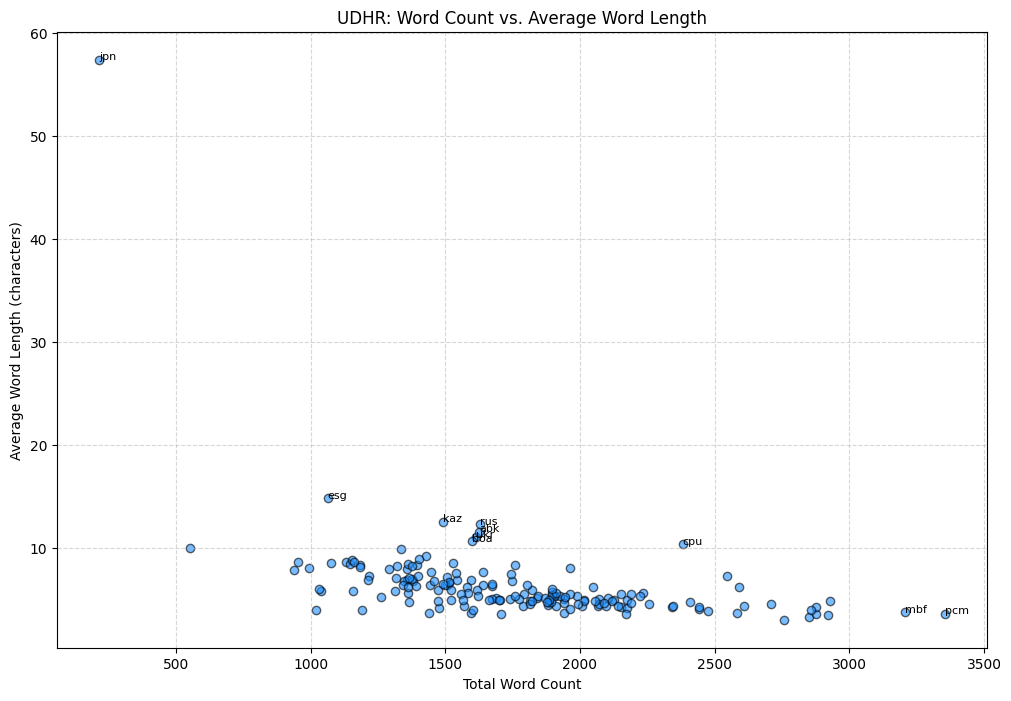

In [9]:
import os
import zipfile
# --- STEP 1: DOWNLOAD AND UNZIP DATA (CONDITIONAL) ---
# Only download if the file doesn't exist yet
if not os.path.exists('udhr.zip'):
    print("Downloading data...")
    !wget -q -O udhr.zip https://ufal.mff.cuni.cz/~zabokrtsky/courses/npfl125/data/udhr.zip

    print("Unzipping data...")
    !unzip -q -o udhr.zip -d udhr_data
else:
    print("Data already downloaded (udhr.zip found). Skipping download.")

    # Optional safety check: If zip exists but folder is missing, unzip it anyway
    if not os.path.exists('udhr_data'):
        print("Folder missing. Unzipping existing file...")
        !unzip -q -o udhr.zip -d udhr_data
data_folder = 'udhr_data/udhr'

filenames = []
word_counts = []
avg_word_lengths = []

print(f"Reading files from: {data_folder}")
# Iterate through every file in the folder
for filename in os.listdir(data_folder):
    file_path = os.path.join(data_folder, filename)

    # Skip directories or hidden files
    if os.path.isdir(file_path) or filename.startswith('.'):
        continue

    try:
        # Open file with 'latin-1' encoding (standard for this specific dataset)
        with open(file_path, 'r', encoding='latin-1', errors='ignore') as f:
            text = f.read()

        # Split text into a list of words
        words = text.split()

        # Calculate metrics if the file is not empty
        if len(words) > 0:
            count = len(words)
            total_chars = sum(len(w) for w in words)
            avg_len = total_chars / count

            # Append data to our lists
            word_counts.append(count)
            avg_word_lengths.append(avg_len)
            filenames.append(filename)

    except Exception as e:
        print(f"Skipping {filename}: {e}")

# --- STEP 3: VISUALIZE ---
print(f"Plotting {len(filenames)} languages...")

plt.figure(figsize=(12, 8))
plt.scatter(word_counts, avg_word_lengths, color='dodgerblue', alpha=0.6, edgecolors='black')

# Add labels and styling
plt.title('UDHR: Word Count vs. Average Word Length')
plt.xlabel('Total Word Count')
plt.ylabel('Average Word Length (characters)')
plt.grid(True, linestyle='--', alpha=0.5)

# Optional: Annotate outliers to identify specific languages
# (e.g., Languages with very long words or very short texts)
for i, name in enumerate(filenames):
    if avg_word_lengths[i] > 10 or word_counts[i] > 3000:
        plt.annotate(name, (word_counts[i], avg_word_lengths[i]), fontsize=8)

plt.show()

Calculating vocabulary size for 169 languages...


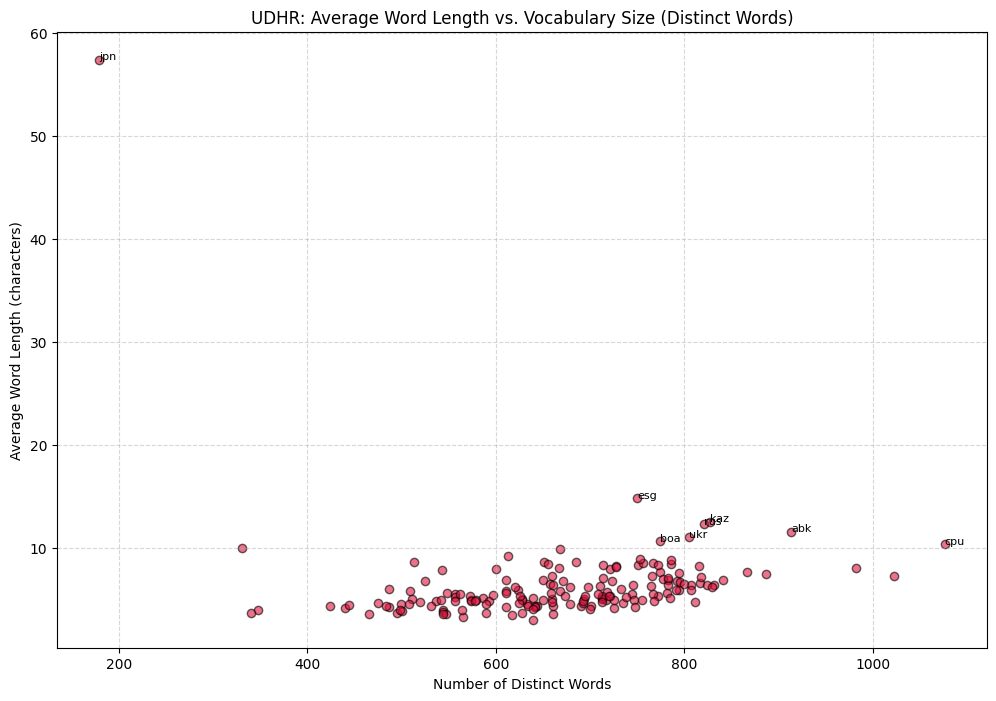

In [11]:
# We reuse the 'filenames' and 'avg_word_lengths' lists from the previous cell
# to ensure the data stays perfectly aligned (same order).

distinct_counts = []

print(f"Calculating vocabulary size for {len(filenames)} languages...")

for name in filenames:
    # Reconstruct the full path using the existing 'data_folder' variable
    file_path = os.path.join(data_folder, name)

    try:
        with open(file_path, 'r', encoding='latin-1', errors='ignore') as f:
            text = f.read()

        # Calculate distinct words (Vocabulary Size)
        # set() removes duplicates, len() counts what remains
        distinct_words = len(set(text.split()))
        distinct_counts.append(distinct_words)

    except Exception as e:
        print(f"Error reading {name}: {e}")
        distinct_counts.append(0) # Placeholder to keep list lengths matching

# --- VISUALIZE ---
plt.figure(figsize=(12, 8))

# X-axis: Distinct Words (New Metric)
# Y-axis: Average Word Length (Existing Metric from previous cell)
plt.scatter(distinct_counts, avg_word_lengths, color='crimson', alpha=0.6, edgecolors='black')

plt.title('UDHR: Average Word Length vs. Vocabulary Size (Distinct Words)')
plt.xlabel('Number of Distinct Words')
plt.ylabel('Average Word Length (characters)')
plt.grid(True, linestyle='--', alpha=0.5)

# Annotate interesting outliers
for i, name in enumerate(filenames):
    # Highlight languages with very high avg length or very large vocabularies
    if avg_word_lengths[i] > 10 or distinct_counts[i] > 1200:
        plt.annotate(name, (distinct_counts[i], avg_word_lengths[i]), fontsize=8)

plt.show()

Loading 12 languages from udhr_data/udhr...


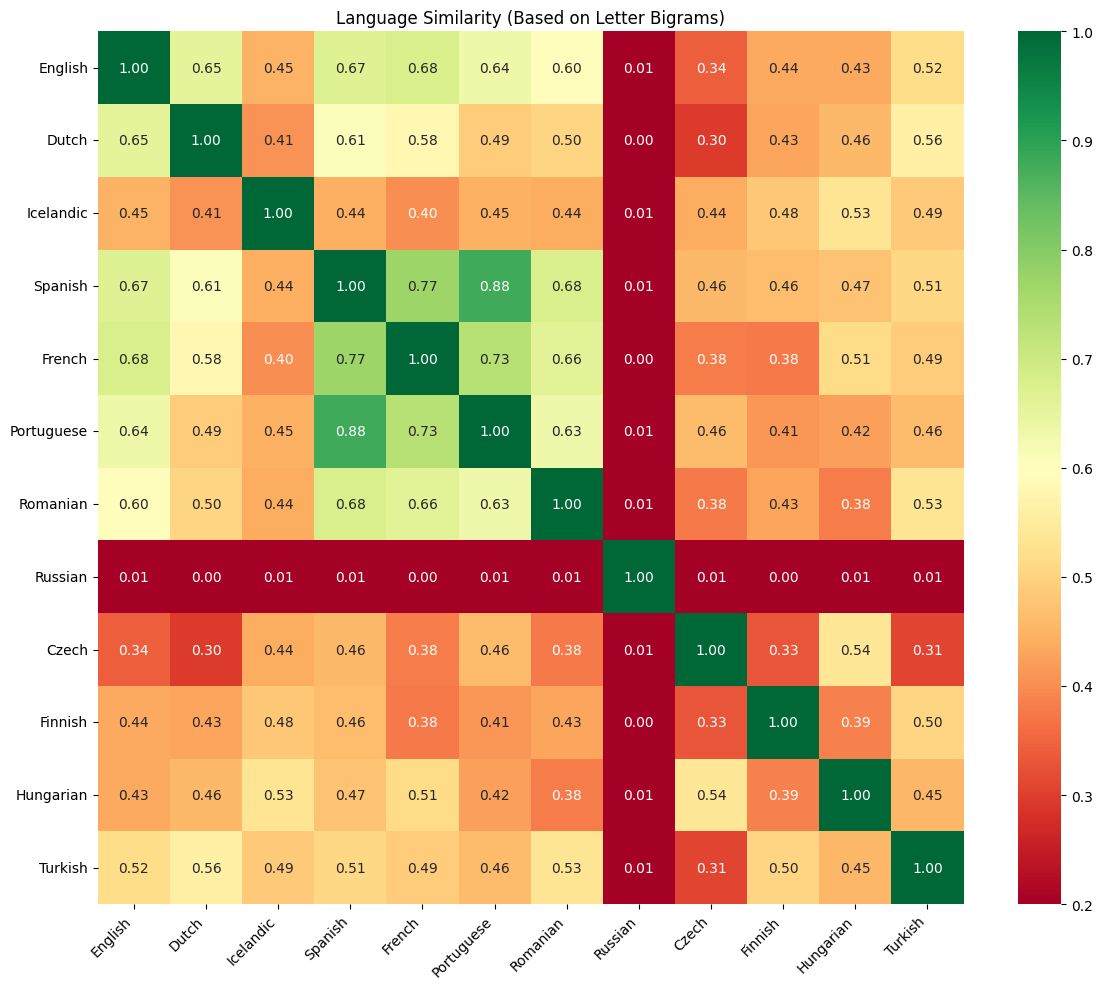

In [13]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import os
import seaborn as sns  # seaborn makes heatmaps look much better

# --- 1. DEFINE THE TARGET LANGUAGES ---
# Mapping the full name to the specific 3-letter code found in your ls output
# Germanic: English, Dutch, Icelandic
# Romance: Spanish, French, Portuguese, Romanian
# Slavic: Russian, Czech
# Uralic/Altaic: Finnish (Suomi), Hungarian, Turkish
target_map = {
    'English': 'eng',
    'Dutch': 'dut',
    'Icelandic': 'ice',
    'Spanish': 'spn',
    'French': 'frn',
    'Portuguese': 'por',
    'Romanian': 'rum',
    'Russian': 'rus',
    'Czech': 'czc',
    'Finnish': 'suo',
    'Hungarian': 'hng',
    'Turkish': 'trk'
}

sample_texts = []
labels = []

print(f"Loading {len(target_map)} languages from {data_folder}...")

# --- 2. LOAD THE TEXTS ---
for lang_name, filename in target_map.items():
    file_path = os.path.join(data_folder, filename)

    if os.path.exists(file_path):
        try:
            # Using latin-1 with ignore to handle diverse encodings safely
            with open(file_path, 'r', encoding='latin-1', errors='ignore') as f:
                text = f.read()
                sample_texts.append(text)
                labels.append(lang_name)
        except Exception as e:
            print(f"Error reading {lang_name} ({filename}): {e}")
    else:
        print(f"Warning: File not found for {lang_name} ({filename})")

# --- 3. COMPUTE SIMILARITY ---
# We use Character Bigrams (pairs of letters) to find similarity
# e.g., Spanish and Portuguese both use "ao", "ue", "es" frequently.
vectorizer = CountVectorizer(analyzer='char', ngram_range=(2, 2))
X = vectorizer.fit_transform(sample_texts)
similarity_matrix = cosine_similarity(X)

# --- 4. VISUALIZE WITH HEATMAP ---
plt.figure(figsize=(12, 10))

# Create heatmap using Seaborn (easier to read than standard matplotlib)
sns.heatmap(similarity_matrix,
            annot=True,         # Show numbers
            fmt=".2f",          # 2 decimal places
            xticklabels=labels,
            yticklabels=labels,
            cmap="RdYlGn",      # Red (Low) to Green (High)
            vmin=0.2, vmax=1.0) # Set range to make colors pop

plt.title("Language Similarity (Based on Letter Bigrams)")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()



Loading files from udhr_data/udhr...


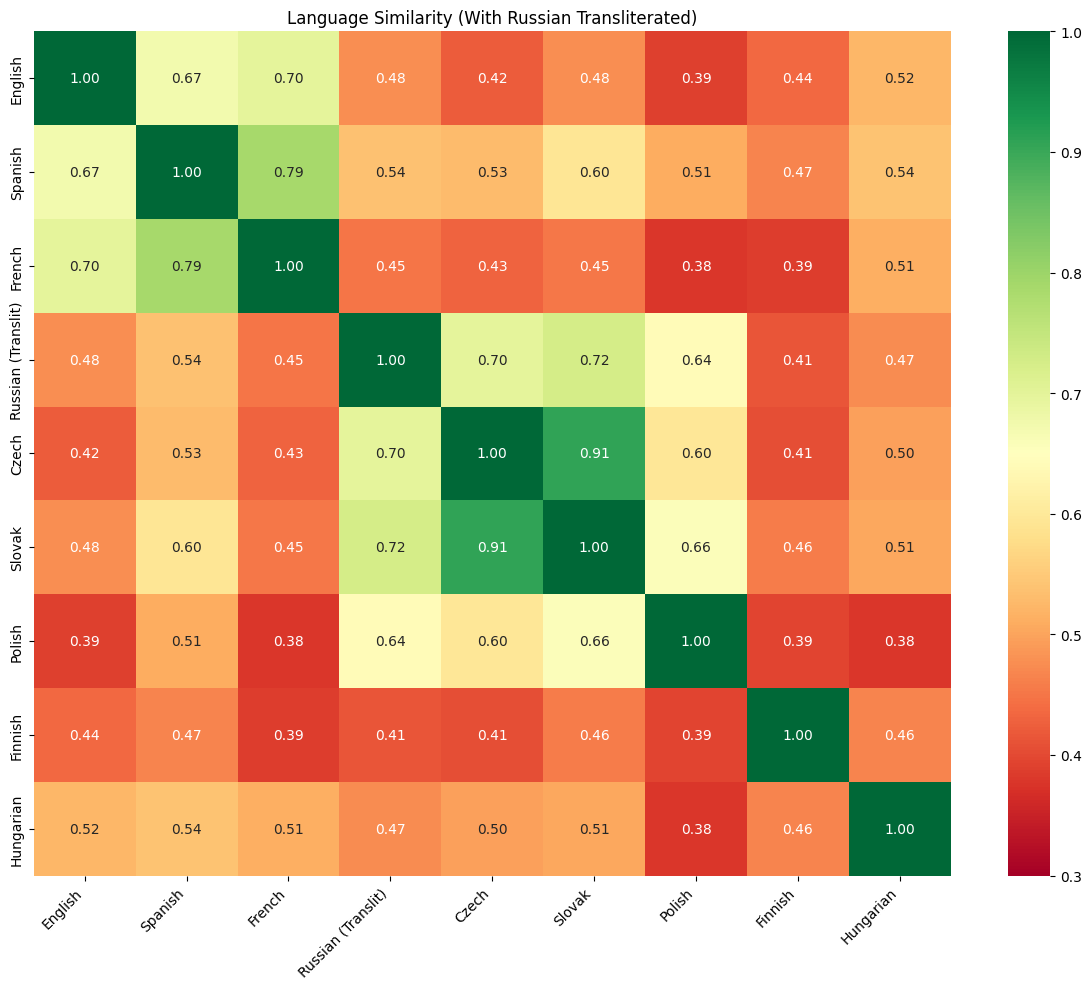

In [18]:
# here i want to convert the russian (which is in azbuka) into the latin so i can compare it with Czech and Slovak language and see if there is high similarity
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# --- 1. SETUP: TRANSLITERATION FUNCTION ---
# This converts Cyrillic characters to their Latin equivalents
def transliterate_rus(text):
    mapping = {
        'а': 'a', 'б': 'b', 'в': 'v', 'г': 'g', 'д': 'd', 'е': 'e', 'ё': 'yo',
        'ж': 'zh', 'з': 'z', 'и': 'i', 'й': 'j', 'к': 'k', 'л': 'l', 'м': 'm',
        'н': 'n', 'о': 'o', 'п': 'p', 'р': 'r', 'с': 's', 'т': 't', 'у': 'u',
        'ф': 'f', 'х': 'kh', 'ц': 'ts', 'ч': 'ch', 'ш': 'sh', 'щ': 'shch',
        'ъ': '', 'ы': 'y', 'ь': '', 'э': 'e', 'ю': 'yu', 'я': 'ya'
    }
    # Convert to lowercase first to simplify mapping
    text = text.lower()
    res = []
    for char in text:
        # Use the mapped character, or keep original if not in map
        res.append(mapping.get(char, char))
    return "".join(res)

# --- 2. DEFINE TARGETS ---
data_folder = 'udhr_data/udhr'  # Ensure this matches your folder path

# We map the display name -> exact 3-letter filename from your 'ls' output
target_map = {
    'English': 'eng',
    'German': 'ger',        # or 'deu', check your folder if this fails
    'Spanish': 'spn',
    'French': 'frn',
    'Russian (Translit)': 'rus', # We will treat this specially
    'Czech': 'czc',
    'Slovak': 'slo',        # 'slo' is the code for Slovak in your list
    'Polish': 'pql',        # 'pql' appears in your list (Standard is 'pol')
    'Finnish': 'suo',
    'Hungarian': 'hng'
}

sample_texts = []
labels = []

print(f"Loading files from {data_folder}...")

# --- 3. LOAD AND PROCESS TEXTS ---
for lang_name, filename in target_map.items():
    file_path = os.path.join(data_folder, filename)

    # Try to find the file (exact match or starting with the code)
    if not os.path.exists(file_path):
        candidates = [f for f in os.listdir(data_folder) if f.startswith(filename)]
        if candidates:
            file_path = os.path.join(data_folder, candidates[0])

    if os.path.exists(file_path):
        try:
            text = ""

            # CASE A: RUSSIAN (Needs specific encoding + Transliteration)
            if 'Russian' in lang_name:
                # Try UTF-8 first, then CP1251 (standard Cyrillic)
                try:
                    with open(file_path, 'r', encoding='utf-8') as f:
                        text = f.read()
                except UnicodeDecodeError:
                    with open(file_path, 'r', encoding='cp1251') as f:
                        text = f.read()

                # Apply the transliteration function
                text = transliterate_rus(text)

            # CASE B: OTHER LANGUAGES (Needs to preserve accents like š, č, ž)
            else:
                try:
                    with open(file_path, 'r', encoding='utf-8') as f:
                        text = f.read()
                except UnicodeDecodeError:
                    # Fallback to Latin-1 if UTF-8 fails (though accents might break)
                    with open(file_path, 'r', encoding='latin-1', errors='ignore') as f:
                        text = f.read()

            sample_texts.append(text)
            labels.append(lang_name)

        except Exception as e:
            print(f"Skipping {lang_name}: {e}")
    else:
        print(f"Warning: File not found for {lang_name} ({filename})")

# --- 4. COMPUTE SIMILARITY & VISUALIZE ---
if sample_texts:
    # Analyze Character Bigrams (ngram_range=(2,2))
    vectorizer = CountVectorizer(analyzer='char', ngram_range=(2, 2))
    X = vectorizer.fit_transform(sample_texts)
    similarity_matrix = cosine_similarity(X)

    # Plot Heatmap
    plt.figure(figsize=(12, 10))
    sns.heatmap(similarity_matrix,
                annot=True,         # Show the numbers
                fmt=".2f",
                xticklabels=labels,
                yticklabels=labels,
                cmap="RdYlGn",      # Red to Green colormap
                vmin=0.3, vmax=1.0) # Start from 0.3 to see better contrast

    plt.title("Language Similarity (With Russian Transliterated)")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("No texts were loaded. Please check your data folder path.")

----------------------------------------------------------------------------------------------------------------------------------------------------------------
Exercises making use of the cs_pdtc-ud-train-ca.conllu (the training part of the Prague Dependency Treebank in Universal Dependencies):
File cs_pdtc-ud-train-ca.conllu not found. Attempting download...
Download successful.
Parsing file...
Plotting data for 5022 sentences...


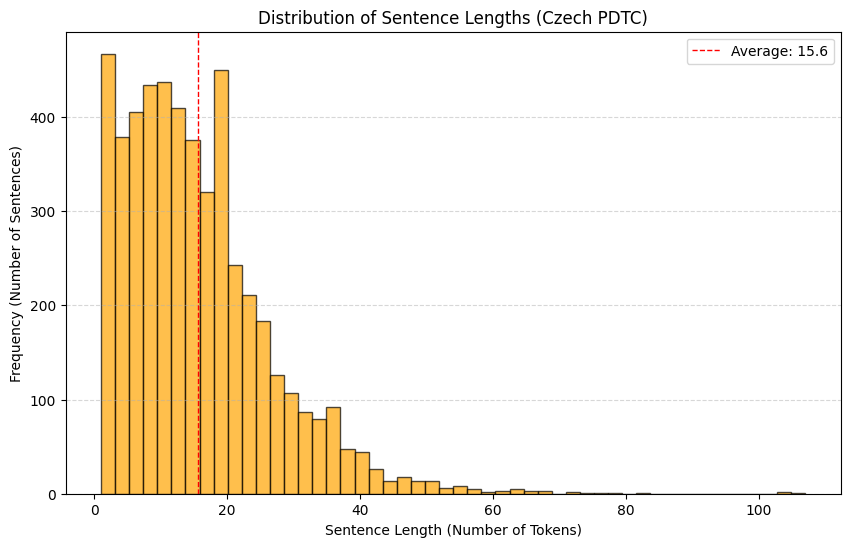

In [16]:
print("----------------------------------------------------------------------------------------------------------------------------------------------------------------")
print("Exercises making use of the cs_pdtc-ud-train-ca.conllu (the training part of the Prague Dependency Treebank in Universal Dependencies):")
# --- STEP 1: LOAD THE DATA ---
filename = 'cs_pdtc-ud-train-ca.conllu'

# If the file isn't here, try downloading it from the likely source (NPFL125 course)
if not os.path.exists(filename):
    print(f"File {filename} not found. Attempting download...")
    # Using the specific URL pattern for the NPFL125 course data
    url = "https://raw.githubusercontent.com/UniversalDependencies/UD_Czech-PDTC/refs/heads/master/cs_pdtc-ud-train-ca.conllu"

    !wget -q {url}

    if os.path.exists(filename):
        print("Download successful.")
    else:
        print("Error: Could not download file. Please check the URL or upload it manually.")

# --- STEP 2: PROCESS THE CONLLU FILE ---
sentence_lengths = []
current_length = 0

if os.path.exists(filename):
    print("Parsing file...")
    with open(filename, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()

            # Empty lines mark the end of a sentence
            if not line:
                if current_length > 0:
                    sentence_lengths.append(current_length)
                    current_length = 0

            # Skip comment lines
            elif line.startswith('#'):
                continue

            # Count tokens
            else:
                parts = line.split('\t')
                # CoNLL-U ID is the first column.
                # We check if it is a digit (e.g., '1', '2') to count syntactic words.
                # We skip multi-word tokens (e.g., '1-2') which are ranges.
                if parts[0].isdigit():
                    current_length += 1

    # Catch the last sentence if the file doesn't end with a newline
    if current_length > 0:
        sentence_lengths.append(current_length)

    # --- STEP 3: VISUALIZE (HISTOGRAM) ---
    print(f"Plotting data for {len(sentence_lengths)} sentences...")

    plt.figure(figsize=(10, 6))

    # Create the histogram
    # bins=range(...) forces the bars to align with integers (1, 2, 3...)
    plt.hist(sentence_lengths, bins=50, color='orange', edgecolor='black', alpha=0.7)

    plt.title('Distribution of Sentence Lengths (Czech PDTC)')
    plt.xlabel('Sentence Length (Number of Tokens)')
    plt.ylabel('Frequency (Number of Sentences)')

    # Add a vertical line for the average length
    avg_len = sum(sentence_lengths) / len(sentence_lengths)
    plt.axvline(avg_len, color='red', linestyle='dashed', linewidth=1, label=f'Average: {avg_len:.1f}')

    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.show()

else:
    print("Skipping processing because file was not found.")